# 30 Day Mapping Challenge

In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pathlib import Path
from rasterio.merge import merge
import numpy as np
from rasterio.windows import from_bounds
from shapely.geometry import box
from rasterio.plot import plotting_extent
from sklearn.neighbors import NearestNeighbors
from shapely.geometry import Polygon, MultiPolygon
from shapely.ops import triangulate
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# SHAPES
tree canopy phily height field added to symbolize

In [2]:
# Load your tree canopy polygons
canopy = gpd.read_file("/Users/sophiameyers/Documents/GitHub/30-day-mapping/data/ppr_tree_canopy_outlines_2015/ppr_tree_canopy_outlines_2015.shp")

# Inspect the data
print(canopy.head())
print(canopy.columns)
print(canopy.crs)
print(canopy.shape)

# Inspect the available attributes
print(canopy.dtypes)

   objectid  avg_height polyid   fcode  shape_leng   shape_area  \
0         2         6.0      3  3000.0   66.000526   279.453508   
1        14        17.0     23  3000.0   70.425045   351.315225   
2        15        32.0     24  3000.0   46.593473   108.578054   
3        19        15.0     28  3000.0   67.783315   293.959714   
4        28        32.0     37  3000.0  979.079210  9433.259404   

                                            geometry  
0  POLYGON ((-75.27506 39.97746, -75.27506 39.977...  
1  POLYGON ((-75.26884 39.97958, -75.26884 39.979...  
2  POLYGON ((-75.2651 39.96519, -75.26512 39.9651...  
3  POLYGON ((-75.27271 39.97838, -75.27271 39.978...  
4  POLYGON ((-75.26491 39.96518, -75.26497 39.965...  
Index(['objectid', 'avg_height', 'polyid', 'fcode', 'shape_leng', 'shape_area',
       'geometry'],
      dtype='str')
EPSG:4326
(193418, 7)
objectid         int32
avg_height     float64
polyid             str
fcode          float64
shape_leng     float64
shape_area 

In [3]:
# Work with a copy of the original data
canopy_map = canopy.copy()

# Remove missing and empty geometries
canopy_map = canopy_map[
    canopy_map.geometry.notna()
    & ~canopy_map.geometry.is_empty
].copy()

# Remove features with missing or non-positive heights
canopy_map = canopy_map[
    canopy_map["avg_height"].notna()
    & (canopy_map["avg_height"] > 0)
].copy()

# Repair invalid geometries if necessary
invalid = ~canopy_map.geometry.is_valid

if invalid.any():
    canopy_map.loc[invalid, "geometry"] = (
        canopy_map.loc[invalid, "geometry"].make_valid()
    )

# Reproject from geographic coordinates to Pennsylvania South State Plane
canopy_map = canopy_map.to_crs("EPSG:2272")

# Calculate polygon areas in square feet
canopy_map["area_sqft"] = canopy_map.geometry.area

# Remove any geometries that remain unsuitable
canopy_map = canopy_map[
    canopy_map.geometry.notna()
    & ~canopy_map.geometry.is_empty
    & canopy_map.geometry.is_valid
    & (canopy_map["area_sqft"] > 0)
].copy()

print("Valid canopy polygons:", len(canopy_map))
print("\nArea distribution (square feet):")
print(canopy_map["area_sqft"].describe())

/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/constructive.py:752: RuntimeWarning: invalid value encountered in make_valid
  return lib.make_valid(geometry, **kwargs)


Valid canopy polygons: 193418

Area distribution (square feet):
count    1.934180e+05
mean     4.184413e+03
std      1.715062e+05
min      5.041088e+00
25%      3.768310e+02
50%      7.537585e+02
75%      1.897274e+03
max      6.823659e+07
Name: area_sqft, dtype: float64


In [8]:
from matplotlib.colors import Normalize, LinearSegmentedColormap

In [9]:
# Height values
heights = largest["avg_height"].astype(float)

# Avoid extreme values dominating the color scale
vmin = heights.quantile(0.02)
vmax = heights.quantile(0.98)

norm = Normalize(vmin=vmin, vmax=vmax, clip=True)

# Custom green palette
height_cmap = LinearSegmentedColormap.from_list(
    "canopy_green",
    [
        "#163D2B",  # Deep forest green
        "#287447",  # Medium green
        "#69A84F",  # Fresh green
        "#C3E879"   # Bright lime
    ]
)

print(f"Height range for color mapping: {vmin:.1f}–{vmax:.1f}")

Height range for color mapping: 11.0–68.0


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rasterio.features import rasterize
from rasterio.transform import from_bounds as raster_transform
from scipy.ndimage import distance_transform_edt, binary_opening
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable

# Keep the original vector geometries and their bounds
minx, miny, maxx, maxy = largest.total_bounds

# Increase rendering resolution instead of decreasing it
GRID_SIZE = 3600

aspect = (maxy - miny) / (maxx - minx)
width = GRID_SIZE
height = max(1, int(GRID_SIZE * aspect))

transform = raster_transform(
    minx, miny, maxx, maxy,
    width=width,
    height=height
)

# Rasterize average canopy height
shapes = [
    (geom, float(value))
    for geom, value in zip(largest.geometry, largest["avg_height"])
    if geom is not None
    and not geom.is_empty
    and pd.notna(value)
]

height_raster = rasterize(
    shapes,
    out_shape=(height, width),
    transform=transform,
    fill=np.nan,
    dtype="float32",
    all_touched=False
)

canopy_mask = np.isfinite(height_raster)

print(f"Raster dimensions: {width:,} × {height:,}")
print(f"Occupied pixels: {canopy_mask.sum():,}")

Raster dimensions: 3,600 × 3,873
Occupied pixels: 585,222


In [29]:
# Remove isolated pixels in the rendered mask.
# This is a display cleanup, not a change to the source geometries.
clean_mask = binary_opening(
    canopy_mask,
    structure=np.ones((3, 3), dtype=bool)
)

# Preserve the height values only where the cleaned mask remains
clean_heights = np.where(clean_mask, height_raster, np.nan)

# Green palette: dark to bright
height_cmap = LinearSegmentedColormap.from_list(
    "canopy_green",
    ["#163D2B", "#287447", "#69A84F", "#C3E879"]
)

# Use robust limits so extreme heights do not dominate the palette
valid_heights = largest["avg_height"].dropna().astype(float)

vmin = valid_heights.quantile(0.02)
vmax = valid_heights.quantile(0.98)

norm = Normalize(vmin=vmin, vmax=vmax, clip=True)

# Assign a base color from average height
normalized = norm(np.nan_to_num(clean_heights, nan=vmin))
rgba = height_cmap(normalized)
rgb = rgba[:, :, :3]

# Calculate distance from the edge of the canopy mask.
# The effect darkens the edge and brightens the interior.
distance_inside = distance_transform_edt(clean_mask)

# Make the gradient broad and visible
edge_gradient = np.clip(distance_inside / 30, 0, 1)

# Darker at edges, brighter toward the interior
edge_shading = 0.25 + 0.52 * edge_gradient

# Add directional lighting across each shape
rows, cols = np.indices(clean_mask.shape)

x_light = cols / max(width - 1, 1)
y_light = rows / max(height - 1, 1)

directional_light = (
    0.82
    + 0.13 * (1 - x_light)
    + 0.10 * (1 - y_light)
)

# Combine the edge shading and directional light
shading = edge_shading * directional_light

# Apply shading to the base height colors
shaded_rgb = np.clip(
    rgb * shading[:, :, None],
    0,
    1
)

# Set transparent pixels outside canopy polygons
shaded_rgba = np.dstack([
    shaded_rgb,
    clean_mask.astype(float)
])

print("Cleaned isolated raster pixels:", int(canopy_mask.sum() - clean_mask.sum()))

Cleaned isolated raster pixels: 22891


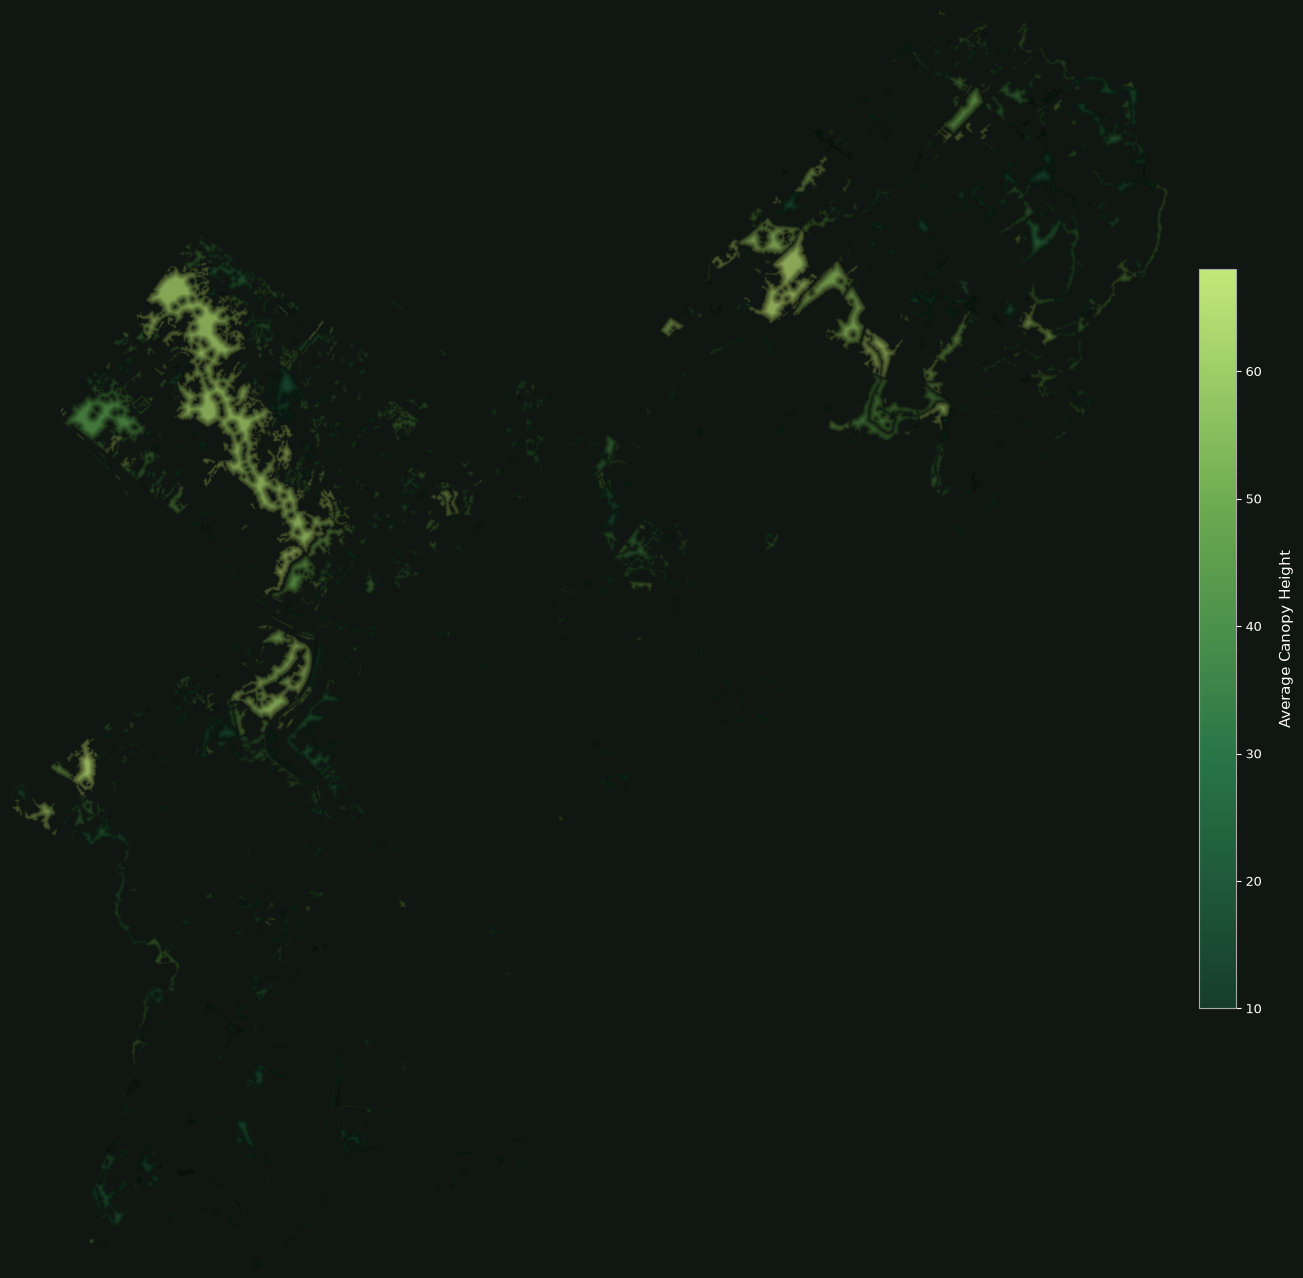

In [30]:
fig, ax = plt.subplots(figsize=(14, 14), facecolor="#101713")

ax.set_facecolor("#101713")

ax.imshow(
    shaded_rgba,
    extent=(minx, maxx, miny, maxy),
    origin="upper",
    interpolation="bilinear"
)

ax.set_xlim(minx, maxx)
ax.set_ylim(miny, maxy)
ax.set_aspect("equal")
ax.axis("off")

# Color legend for average canopy height
sm = ScalarMappable(norm=norm, cmap=height_cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.035,
    pad=0.025,
    shrink=0.55
)

cbar.set_label(
    "Average Canopy Height",
    color="white",
    fontsize=11,
    labelpad=12
)

cbar.ax.tick_params(colors="white", labelsize=9)
cbar.outline.set_edgecolor("#AAAAAA")

fig.subplots_adjust(
    left=0.02,
    right=0.90,
    top=0.98,
    bottom=0.02
)

plt.savefig(
    "philadelphia_canopy_shape_gradient.png",
    dpi=300,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

### super smoother top 1000

In [46]:
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from shapely import make_valid
from rasterio.features import rasterize
from rasterio.transform import from_bounds as raster_transform
from scipy.ndimage import distance_transform_edt
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable

# Keep valid polygons with positive area and a known average height
canopy_clean = canopy_map[
    canopy_map.geometry.notna()
    & ~canopy_map.geometry.is_empty
    & canopy_map["avg_height"].notna()
    & (canopy_map.geometry.area > 0)
].copy()

# Recalculate area in projected units
canopy_clean["area_sqft"] = canopy_clean.geometry.area

# Select the 1,000 largest polygons
largest = (
    canopy_clean
    .nlargest(300, "area_sqft")
    .copy()
    .reset_index(drop=True)
)

print(f"Selected {len(largest):,} polygons")

Selected 300 polygons


In [47]:
# Increase this for rounder, more oval-like shapes
SMOOTHING_DISTANCE = 70  # feet; experiment with 10–40

def smooth_polygon(geom, distance):
    if geom is None or geom.is_empty:
        return geom

    try:
        # Repair geometry before smoothing
        geom = make_valid(geom)

        # Round corners and reduce small boundary irregularities
        smoothed = geom.buffer(
            distance,
            quad_segs=12
        ).buffer(
            -distance,
            quad_segs=12
        )

        if smoothed.is_empty:
            return geom

        return smoothed

    except Exception:
        return geom

largest["geometry"] = largest.geometry.apply(
    lambda geom: smooth_polygon(geom, SMOOTHING_DISTANCE)
)

# Remove empty geometries after smoothing
largest = largest[
    largest.geometry.notna()
    & ~largest.geometry.is_empty
    & (largest.geometry.area > 0)
].copy()

print(f"Polygons remaining after smoothing: {len(largest):,}")

/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(


Polygons remaining after smoothing: 300


In [48]:
# Get bounds after smoothing
minx, miny, maxx, maxy = largest.total_bounds

# High-resolution rendering
GRID_SIZE = 5000

aspect = (maxy - miny) / (maxx - minx)
width = GRID_SIZE
height = max(1, int(GRID_SIZE * aspect))

transform = raster_transform(
    minx, miny, maxx, maxy,
    width=width,
    height=height
)

# Rasterize average height values
shapes = [
    (geom, float(value))
    for geom, value in zip(largest.geometry, largest["avg_height"])
    if geom is not None
    and not geom.is_empty
    and pd.notna(value)
]

height_raster = rasterize(
    shapes,
    out_shape=(height, width),
    transform=transform,
    fill=np.nan,
    dtype="float32",
    all_touched=False
)

canopy_mask = np.isfinite(height_raster)

print(f"Rendering grid: {width:,} × {height:,}")

Rendering grid: 5,000 × 5,208


In [49]:
# Green color ramp
height_cmap = LinearSegmentedColormap.from_list(
    "canopy_green",
    ["#2FFF00", "#7BFF00", "#BBFF00", "#FBFF00"]
)

# Color normalization based on the height distribution
valid_heights = largest["avg_height"].astype(float)

vmin = valid_heights.quantile(0.02)
vmax = valid_heights.quantile(0.98)

norm = Normalize(vmin=vmin, vmax=vmax, clip=True)

normalized = norm(
    np.nan_to_num(height_raster, nan=vmin)
)

rgba = height_cmap(normalized)
rgb = rgba[:, :, :3]

# Calculate distance from the nearest edge within the canopy mask
distance_inside = distance_transform_edt(canopy_mask)

# Broader, stronger interior gradient
edge_gradient = np.clip(distance_inside / 45, 0, 1)
edge_shading = 0.40 + 0.60 * edge_gradient

# Directional lighting
rows, cols = np.indices(canopy_mask.shape)

directional_light = (
    0.82
    + 0.12 * (1 - cols / max(width - 1, 1))
    + 0.10 * (1 - rows / max(height - 1, 1))
)

shading = edge_shading * directional_light

shaded_rgb = np.clip(
    rgb * shading[:, :, None],
    0,
    1
)

shaded_rgba = np.dstack([
    shaded_rgb,
    canopy_mask.astype(float)
])

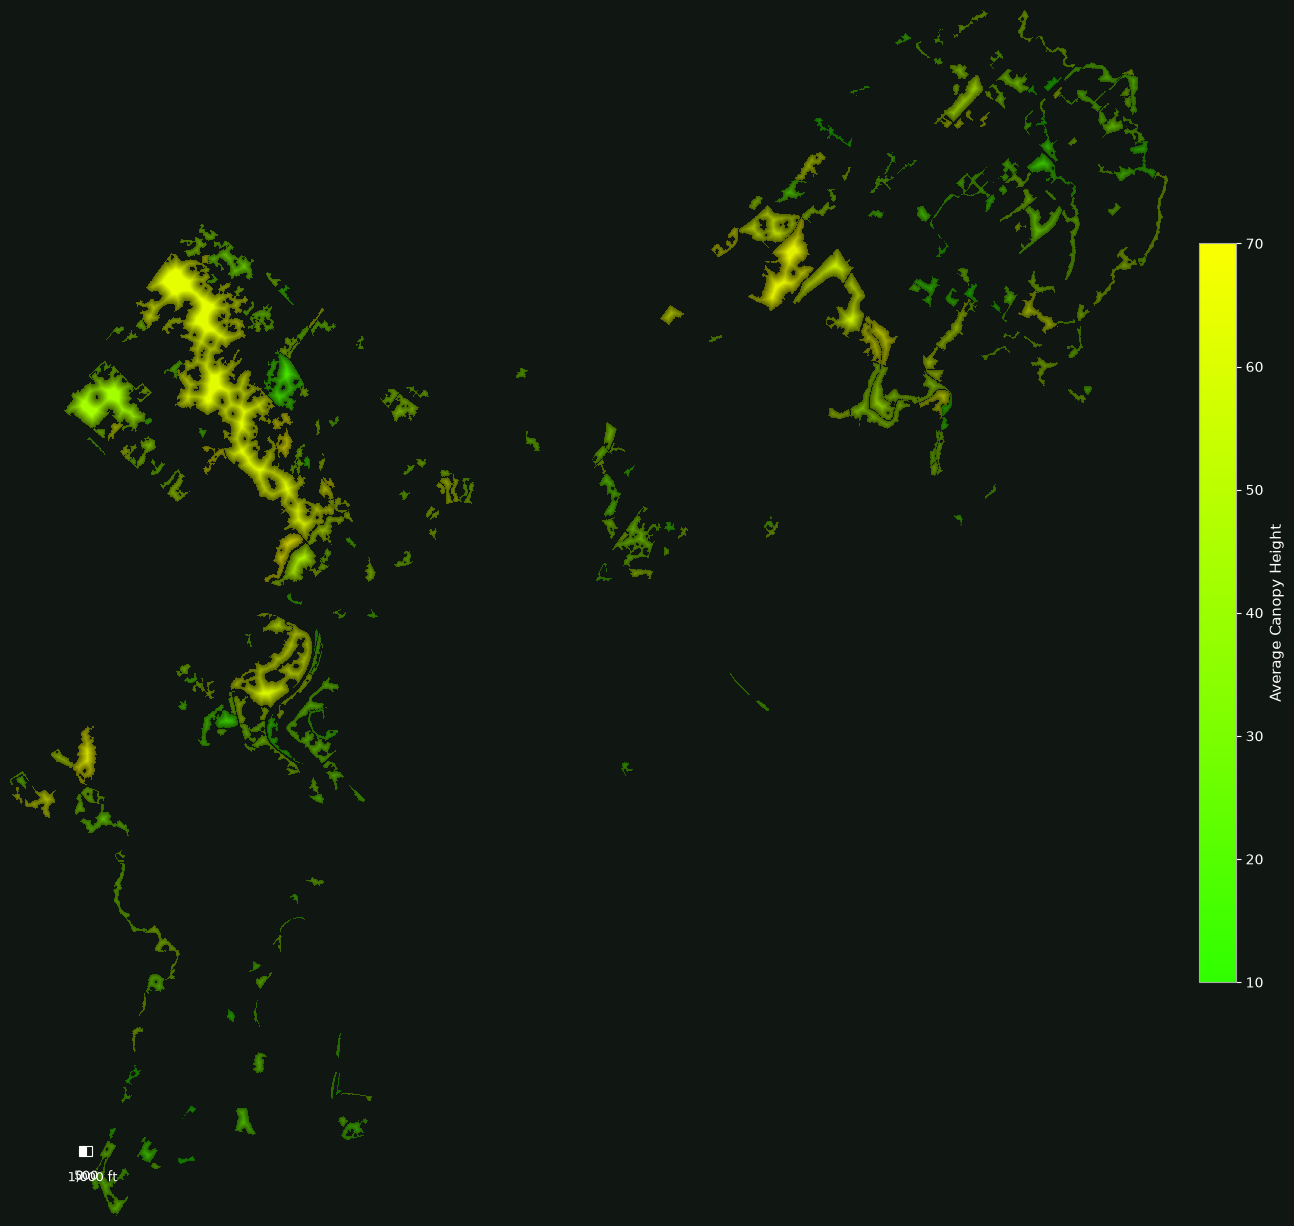

In [51]:
fig, ax = plt.subplots(
    figsize=(14, 14),
    facecolor="#101713"
)

ax.set_facecolor("#101713")

ax.imshow(
    shaded_rgba,
    extent=(minx, maxx, miny, maxy),
    origin="upper",
    interpolation="nearest"
)

# # Draw sharp borders around every canopy polygon
# largest.boundary.plot(
#     ax=ax,
#     color="#1A7800",  # Dark green outline
#     linewidth=0.5,
#     alpha=1.0,
#     zorder=3
# )

ax.set_xlim(minx, maxx)
ax.set_ylim(miny, maxy)
ax.set_aspect("equal")
ax.axis("off")

# Average height legend
sm = ScalarMappable(norm=norm, cmap=height_cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.035,
    pad=0.025,
    shrink=0.55
)

cbar.set_label(
    "Average Canopy Height",
    color="white",
    fontsize=11
)

cbar.ax.tick_params(colors="white")
cbar.outline.set_edgecolor("#AAAAAA")

fig.subplots_adjust(
    left=0.02,
    right=0.90,
    top=0.98,
    bottom=0.02
)

from matplotlib.patches import Rectangle

# Scale bar length in feet (1,000 feet)
scale_length = 1000

# Position relative to the map extent
x_start = minx + (maxx - minx) * 0.06
y_start = miny + (maxy - miny) * 0.05

# Bar height in map units
bar_height = (maxy - miny) * 0.008

# Two alternating segments
segment_length = scale_length / 2

ax.add_patch(
    Rectangle(
        (x_start, y_start),
        segment_length,
        bar_height,
        facecolor="white",
        edgecolor="white",
        linewidth=0.8,
        zorder=10
    )
)

ax.add_patch(
    Rectangle(
        (x_start + segment_length, y_start),
        segment_length,
        bar_height,
        facecolor="#101713",
        edgecolor="white",
        linewidth=0.8,
        zorder=10
    )
)

# Scale bar labels
label_y = y_start - bar_height * 1.5

ax.text(
    x_start,
    label_y,
    "0",
    color="white",
    fontsize=9,
    ha="center",
    va="top",
    zorder=11
)

ax.text(
    x_start + segment_length,
    label_y,
    "500",
    color="white",
    fontsize=9,
    ha="center",
    va="top",
    zorder=11
)

ax.text(
    x_start + scale_length,
    label_y,
    "1,000 ft",
    color="white",
    fontsize=9,
    ha="center",
    va="top",
    zorder=11
)

plt.savefig(
    "philadelphia_top1000_smooth_gradient.svg",
    format="svg",
    facecolor=fig.get_facecolor(),
    bbox_inches="tight",
    pad_inches=0.05
)

# Clusters